# 06 · Z gate on a large cat qubit (Sec. VI, Figs. 1 and 10)

Memory $a$ and buffer $b$ in the rotating frame (Eqs. 57–58):
$$H=g_2a^{\dagger2}b+g_2a^2b^\dagger+\epsilon_d(b+b^\dagger)+\epsilon_Z(a+a^\dagger),\qquad L_b=\sqrt{\kappa_b}\,b,\quad L_a=\sqrt{\kappa_a}\,a .$$
Parameters of Sec. VI B: $g_2=1$, $\kappa_b=10$, $\epsilon_Z=0.1\cdot4g_2^2/\kappa_b$, $\theta=\pi$, $\kappa_a=0$, $|\alpha|^2=2^{R_a}/3$, $R_b=4$. Gate time $T_Z=\theta/(4|\alpha|\epsilon_Z)$; predicted phase-flip error $p_Z=\pi/(40|\alpha|^3)$ (Eq. 66).

**Conventions we had to fix** (the paper leaves them implicit):
* For a real $\alpha$, the stabilised manifold $a^2|\psi\rangle=\alpha^2|\psi\rangle$ with an empty buffer requires $\epsilon_d=-g_2|\alpha|^2$; we checked that $\|H_{\rm eff}\psi_0\|\approx 0$ with this sign.
* Initial state: even cat $|C^+_\alpha\rangle\otimes|0\rangle_b$ (the $|+\rangle$ state). After a $\pi$ rotation the ideal state is the odd cat, so $p_Z=(1+\langle P_a\rangle)/2$ with $P_a$ the memory parity.

In [1]:
import os, sys
from tutorial_utils import *
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(backend_banner())
PAPER_SIZE = HAVE_QTTLIND and os.environ.get("QTTLIND_PAPER_SIZE") == "1"   # published sizes (hours); default: quick mode

qttlind 2.0.0, QTT solver: quick mode (set QTTLIND_PAPER_SIZE=1 for the published sizes).


In [2]:
import scipy.sparse as sp
G2, KB = 1.0, 10.0
EZ = 0.1 * 4 * G2**2 / KB
THETA = np.pi

def cat_model(Ra, Rb=4, kphi=0.0, ka=0.0, drive=True):
    Na, Nb = 2**Ra, 2**Rb
    alpha = np.sqrt(Na / 3)
    a1, b1 = sp.csr_matrix(dr.destroy(Na)), sp.csr_matrix(dr.destroy(Nb))
    Ia, Ib = sp.identity(Na, format="csr"), sp.identity(Nb, format="csr")
    a, b = sp.kron(a1, Ib, format="csr"), sp.kron(Ia, b1, format="csr")
    ad, bd = a.conj().T.tocsr(), b.conj().T.tocsr()
    ed = -G2 * alpha**2
    H = G2 * (ad @ ad @ b) + G2 * (a @ a @ bd) + ed * (b + bd) + (EZ * (a + ad) if drive else 0 * a)
    Ls = [np.sqrt(KB) * b]
    if ka: Ls.append(np.sqrt(ka) * a)
    if kphi: Ls.append(np.sqrt(kphi) * (ad @ a))
    psi0 = dr.kron(dr.cat(Na, alpha, +1), dr.basis(Nb, 0))
    P = sp.kron(sp.diags((-1.0)**np.arange(Na)), Ib, format="csr")
    TZ = THETA / (4 * alpha * EZ)
    Emax = G2 * Na * np.sqrt(Nb) + 2 * abs(ed) * np.sqrt(Nb) + KB * Nb / 2 + 2 * EZ * np.sqrt(Na) + kphi * Na**2
    h = min(2e-3, 0.5 / Emax)
    return dict(H=H.tocsr(), Ls=Ls, psi0=psi0, P=P, TZ=TZ, h=h, alpha=alpha, Na=Na, Nb=Nb)

for Ra in (4, 6, 8):
    m = cat_model(Ra, drive=False)
    print(f"Ra={Ra}: |alpha|^2 = {m['alpha']**2:6.2f}, dark-state residual ||H_eff psi0|| (no drive) = "
          f"{np.linalg.norm(dr.heff(m['H'], m['Ls']) @ m['psi0']):.1e}")
print("-> the residual is pure Fock truncation: it vanishes once N_a comfortably exceeds |alpha|^2")

Ra=4: |alpha|^2 =   5.33, dark-state residual ||H_eff psi0|| (no drive) = 2.2e-01
Ra=6: |alpha|^2 =  21.33, dark-state residual ||H_eff psi0|| (no drive) = 2.0e-05
Ra=8: |alpha|^2 =  85.33, dark-state residual ||H_eff psi0|| (no drive) = 2.2e-12
-> the residual is pure Fock truncation: it vanishes once N_a comfortably exceeds |alpha|^2


## Fig. 10c–d — gate error and run time versus cat size

Without the QTT solver we sweep $R_a=2\ldots5$ ($|\alpha|^2\approx1.3$–$10.7$, up to $D=512$); with `qttlind` the paper's range up to $|\alpha|^2\approx 2000$ ($R_a=13$).

In [3]:
Ras = list(range(2, 6)) if not PAPER_SIZE else list(range(1, 14))
rows, snaps = [], {}
for Ra in Ras:
    m = cat_model(Ra)
    t0 = time.perf_counter()
    if HAVE_QTTLIND and PAPER_SIZE:
        sysq = ql.System(); A = sysq.add_mode("memory", bits=Ra); B = sysq.add_mode("buffer", bits=4)
        Hq = G2 * A.dag()**2 * B + G2 * A**2 * B.dag() - G2 * m["alpha"]**2 * (B + B.dag()) + EZ * (A + A.dag())
        sol = ql.LindbladSolver(sysq, Hq, [np.sqrt(KB) * B], scheme="kraus2", dt=m["h"], tol=1e-8)
        r = sol.run(sysq.product_state(memory=ql.states.cat(m["alpha"], parity=+1), buffer=ql.states.fock(0)),
                    t_final=m["TZ"], e_ops={"P": A.parity()}, every=max(1, int(m["TZ"] / m["h"] / 40)),
                    track=["chi_q", "chi_e", "chi_mu"])
        Pf = np.real(r.expect["P"][-1]); snaps[Ra] = r
    else:
        every = max(1, int(m["TZ"] / m["h"] / 40))
        r = dr.evolve(m["psi0"], m["H"], m["Ls"], m["TZ"], m["h"], e_ops={"P": m["P"]},
                      every=every, rtol=1e-8, keep_states=Ra >= 4)
        Pf = np.real(r.expect["P"][-1]); snaps[Ra] = r
    dt_wall = time.perf_counter() - t0
    rows.append((Ra, m["alpha"]**2, (1 + Pf) / 2, np.pi / (40 * m["alpha"]**3), dt_wall))
    print(f"Ra={Ra}: |alpha|^2={m['alpha']**2:7.2f}  p_Z={(1+Pf)/2:.3e}  theory={np.pi/(40*m['alpha']**3):.3e}  "
          f"steps={int(round(m['TZ']/m['h']))}  wall={dt_wall:.1f}s")
rows = np.array(rows)

Ra=2: |alpha|^2=   1.33  p_Z=3.688e-01  theory=5.101e-02  steps=8502  wall=2.3s


Ra=3: |alpha|^2=   2.67  p_Z=1.094e-01  theory=1.804e-02  steps=6012  wall=11.2s


Ra=4: |alpha|^2=   5.33  p_Z=9.648e-03  theory=6.377e-03  steps=4251  wall=34.5s


Ra=5: |alpha|^2=  10.67  p_Z=2.434e-03  theory=2.254e-03  steps=3532  wall=9.7s


### Quick-mode cross-check: the QTT solver on the cat qubit

In quick mode the figure above comes from the dense oracle. The cell below runs the **QTT solver**
(`ql.LindbladSolver` on the comb) on the same two-mode model at $R_a=R_b=3$ for 300 steps and
compares the memory parity and the purity with the oracle running the same Kraus scheme. With
`QTTLIND_PAPER_SIZE=1` the whole figure is computed by the QTT solver instead.

In [4]:
checks = globals().get("checks", {})
if HAVE_QTTLIND and not PAPER_SIZE:
    mq = cat_model(3, Rb=3)
    nq = 300
    sysq = ql.System(); A = sysq.add_mode("memory", bits=3); B = sysq.add_mode("buffer", bits=3)
    Hq = G2 * A.dag()**2 * B + G2 * A**2 * B.dag() - G2 * mq["alpha"]**2 * (B + B.dag()) + EZ * (A + A.dag())
    sol = ql.LindbladSolver(sysq, Hq, [np.sqrt(KB) * B], scheme="kraus2", dt=mq["h"], tol=1e-12)
    with timer("QTT solver, 300 steps"):
        rq = sol.run(sysq.product_state(memory=ql.states.cat(mq["alpha"], parity=+1), buffer=ql.states.fock(0)),
                     t_final=nq * mq["h"], e_ops={"P": A.parity()}, every=30, track=["purity", "chi_e", "chi_q", "chi_mu"])
    with timer("dense oracle, 300 steps"):
        rd = dr.evolve(mq["psi0"], mq["H"], mq["Ls"], nq * mq["h"], mq["h"], e_ops={"P": mq["P"]}, every=30, rtol=1e-12)
    errP = np.abs(np.real(rq.expect["P"]) - np.real(rd.expect["P"])).max()
    errpur = np.abs(np.asarray(rq.track["purity"]) - np.asarray(rd.purity)).max()
    print(f"max |P_qtt - P_oracle| = {errP:.1e}, max |purity_qtt - purity_oracle| = {errpur:.1e}")
    print("comb bonds at the end:", rq.final_state.bond_dims())
    checks["cat qubit: QTT vs oracle parity"] = (errP, 1e-6)
    checks["cat qubit: QTT vs oracle purity"] = (errpur, 1e-6)

/tmp/ipykernel_3493/1998989376.py:9: CutoffWarning: mode 'memory': <n> = 2.59 at t = 0 is close to its cutoff of 8 levels (<n> + 4 sqrt(<n>) >= levels); increase its bits
  rq = sol.run(sysq.product_state(memory=ql.states.cat(mq["alpha"], parity=+1), buffer=ql.states.fock(0)),


[QTT solver, 300 steps] 27.08 s


[dense oracle, 300 steps] 0.38 s
max |P_qtt - P_oracle| = 1.2e-07, max |purity_qtt - purity_oracle| = 4.9e-08
comb bonds at the end: {'chi_e': 8, 'chi_q': 8, 'chi_mu': 32}


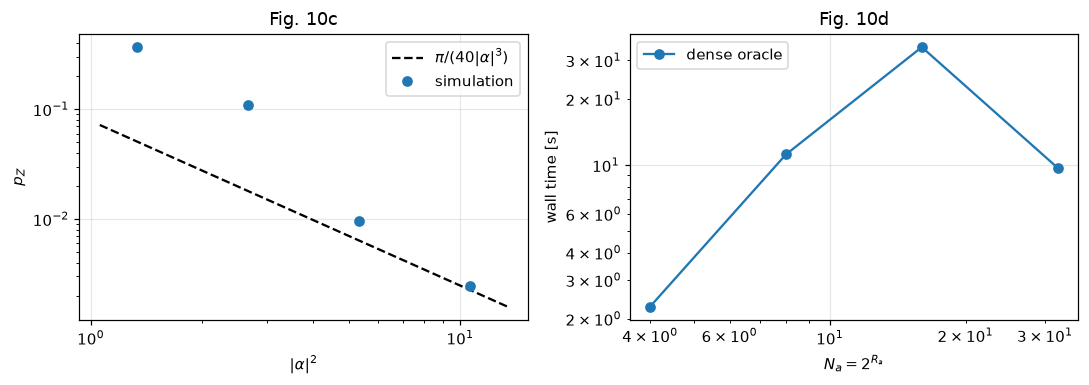

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
xx = np.logspace(np.log10(rows[:, 1].min()) - 0.1, np.log10(rows[:, 1].max()) + 0.1, 50)
ax[0].loglog(xx, np.pi / (40 * xx**1.5), "k--", label=r"$\pi/(40|\alpha|^3)$")
ax[0].loglog(rows[:, 1], rows[:, 2], "o", label="simulation")
ax[0].set(xlabel=r"$|\alpha|^2$", ylabel=r"$p_Z$", title="Fig. 10c"); ax[0].legend()
ax[1].loglog(2**rows[:, 0], rows[:, 4], "o-", label="qttlind" if (HAVE_QTTLIND and PAPER_SIZE) else "dense oracle")
ax[1].set(xlabel=r"$N_a=2^{R_a}$", ylabel="wall time [s]", title="Fig. 10d"); ax[1].legend()
plt.tight_layout(); savefig(fig, "fig10cd_cat_error_time.png"); plt.show()

The dense oracle's wall time grows with $N_a$ (our timings are indicative only: they vary with $\chi_\mu$ and with machine load); the paper's QTT solver grows like $\log N_a$ (its Fig. 10d). Running the cell above with `PAPER_SIZE=True` overlays the two once the core is built. Deviations from Eq. 66 at small $|\alpha|^2$ are expected: the formula is asymptotic, the adiabatic condition $8|\alpha|g_2\ll\kappa_b$ is only marginally met, and the paper's rule $N_a=3|\alpha|^2$ truncates small cats noticeably (at $R_a=3$ the error is dominated by truncation). From $R_a=5$ on, simulation and Eq. 66 agree within ~10%.

## Fig. 10b — quantics bond dimension during the gate

The largest quantics bond is the one joining the memory leg to the backbone, bounded by $2^{R_a}$; the paper's inset plots $2^{R_a}/\chi_q$. It plateaus early in the gate and the plateau does not grow with $R_a$ — that is why the QTT cost stays flat as the cat grows. From the stored states we compute the *optimal* comb bond dimensions of $\Psi(t)$ at tolerance $10^{-8}$ (the numerical rank of every tree cut). This is exactly what the QTT solver would carry, without running it.

compression factor 2^Ra / chi_q at the end: {4: 1.0, 5: 2.0}


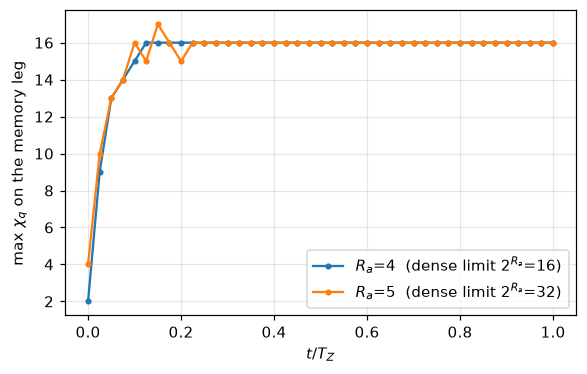

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for Ra in [R for R in snaps if hasattr(snaps[R], "states") and snaps[R].states]:
    r = snaps[Ra]
    chiq = [max(comb_ranks(s.Psi, [Ra, 4], tol=1e-8)["chi_q"][0]) for s in r.states]
    ax.plot(r.times / r.times[-1], chiq, "o-", ms=3, label=rf"$R_a$={Ra}  (dense limit $2^{{R_a}}$={2**Ra})")
ax.set(xlabel=r"$t/T_Z$", ylabel=r"max $\chi_q$ on the memory leg"); ax.legend()
print("compression factor 2^Ra / chi_q at the end:", {Ra: 2**Ra / max(comb_ranks(snaps[Ra].states[-1].Psi, [Ra, 4], tol=1e-8)["chi_q"][0]) for Ra in snaps if getattr(snaps[Ra], "states", None)})
savefig(fig, "fig10b_chi_q.png"); plt.show()

## Fig. 1 — what each compression axis buys

Final state of the gate at $R_a=R_b=3$ (dense-oracle size; use larger $R$ with `qttlind`) for increasing dephasing $L_\varphi=\sqrt{\kappa_\varphi}\,a^\dagger a$ (the paper does not list its $\kappa_\varphi$ values; we use multiples of $\kappa_2=4g_2^2/\kappa_b=0.4$). Bars: number of complex entries for the full $\rho$, then with purification, inter-mode MPS and quantics legs switched on.

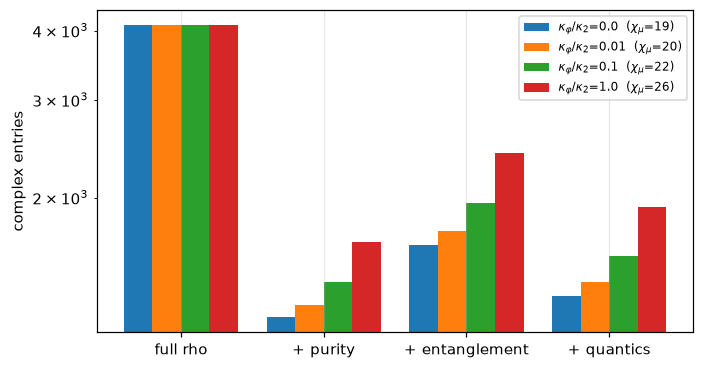

0.0 {'chi_mu': 19, 'chi_e': [8], 'chi_q': [[8, 4, 2], [5, 4, 2]]}
0.01 {'chi_mu': 20, 'chi_e': [8], 'chi_q': [[8, 4, 2], [5, 4, 2]]}
0.1 {'chi_mu': 22, 'chi_e': [8], 'chi_q': [[8, 4, 2], [5, 4, 2]]}
1.0 {'chi_mu': 26, 'chi_e': [8], 'chi_q': [[8, 4, 2], [5, 4, 2]]}


In [7]:
k2 = 4 * G2**2 / KB
stages = {}
for frac in (0.0, 0.01, 0.1, 1.0):
    m = cat_model(3, Rb=3, kphi=frac * k2)
    r = dr.evolve(m["psi0"], m["H"], m["Ls"], m["TZ"], m["h"], every=int(round(m["TZ"] / m["h"])),
                  rtol=1e-8, keep_states=True)
    stages[frac] = compression_stages(r.states[-1].Psi, [3, 3], tol=1e-8)
labels = ["full rho", "+ purity", "+ entanglement", "+ quantics"]
fig, ax = plt.subplots(figsize=(7, 3.8))
wbar = 0.2
for i, (frac, s) in enumerate(stages.items()):
    ax.bar(np.arange(4) + (i - 1.5) * wbar, [s[l] for l in labels], wbar,
           label=rf"$\kappa_\varphi/\kappa_2$={frac}  ($\chi_\mu$={s['ranks']['chi_mu']})")
ax.set_yscale("log"); ax.set_xticks(range(4)); ax.set_xticklabels(labels)
ax.set(ylabel="complex entries"); ax.legend(fontsize=8)
savefig(fig, "fig01_compression_axes.png"); plt.show()
for frac, s in stages.items():
    print(frac, s["ranks"])

At these small sizes (8 states per mode) the MPS and quantics stages cost *more* than they save: their per-tensor overhead exceeds the tiny dense modes. Their gain appears only as $N_a$ grows, which is the point of Fig. 10d; rerun with `qttlind` at $R_a\ge 8$ to see the paper's bars. The ordering of the bars with $\kappa_\varphi$ — more dephasing, larger $\chi_\mu$, $\chi_e$ and $\chi_q$ — is the paper's message.